# Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from model import HourlySeries
from simulations import StructuralModel, Simulation
from estimation import IVOptions, ModelInputParams, interval
from database import Areas
from synthetic import NonLinearDemand, Consumption, RandomCached, average_supply_price, Supply, get_wind_series, WindOptions, NonLinEquilibrium, IndividualDemand
from synthetic import SUPPLY_INTERCEPT, SUPPLY_SIGMA, SUPPLY_SLOPE

In [ ]:
WIND_LAGS: int = 26

ESTIMATORS = [
    ModelInputParams(IVOptions.REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.CONDITIONAL_WIND, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND_CAPPED, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=WIND_LAGS),
]

ESTIMATORS = [
    ModelInputParams(IVOptions.NL_REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1, order_w=0),
    ModelInputParams(IVOptions.CONDITIONAL_H0, order=WIND_LAGS),
    # ModelInputParams(IVOptions.NL_CONDITIONAL_H0, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_TRUNCATED_NUISANCE_ORDER, order=WIND_LAGS, order_d=1),
    ModelInputParams(IVOptions.NL_CLEAN_2dim_ORDER, order=WIND_LAGS, order_price=1),
    ModelInputParams(IVOptions.NL_TRUNCATED_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),
    ModelInputParams(IVOptions.NL_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),
]

AREA = Areas.DE2

# np.random.


In [3]:
YEARS = 10

sample: int = 8760*YEARS
runs: int = 1
model:StructuralModel = StructuralModel.Model_V
wind_manual_ar_sum: float | None = None

INTERVAL = interval(
    start=pd.Timestamp("201901010000"), end=pd.Timestamp("201901010000")+pd.Timedelta(hours=sample)
)

SERIES = HourlySeries(INTERVAL)

# Testing

In [4]:
consumption_analysis_interval: pd.DatetimeIndex = interval(
        start=pd.Timestamp("201901010000"), end=pd.Timestamp("202001282300")
    )

average_demand = Consumption(
            start=consumption_analysis_interval.min(),
            end=consumption_analysis_interval.max(),
            price_area=AREA,
        )().mean()

average_price = average_supply_price(
            quantity=average_demand,
            series=HourlySeries(consumption_analysis_interval),
            price_area=AREA,
        )

In [5]:
SUPPLY = Supply(
    price_area=AREA,
    wind=get_wind_series(
        wind_type=WindOptions.SYNTHETIC_AR_N,
        series=SERIES,
        price_area=AREA,
        synthetic_nlags=WIND_LAGS,
        synthetic_n_observations=sample,
        manual_lags_sum=wind_manual_ar_sum,
    ),
    # error=RandomCached.normal(0, 1),
    # error=RandomCached.normal(0, 500),
    error=RandomCached.normal(0, 1_000),
    slope=SUPPLY_SLOPE,
    intercept=SUPPLY_INTERCEPT-20_000,
)

In [6]:
price = 57
(9000 + price * (-80) + price**2 * (-0.05)) / 0.1

42775.5

In [7]:
DEMAND = NonLinearDemand(
    base_constant=average_demand,
    lags={-1: 0.6},
    b_lin=-20,
    b_sqr=-1.5,
    error=RandomCached.normal(0, 4_000),
    # error=RandomCached.normal(0, 20),
    average_supply_price=average_price,
    cross_price_elasticity={},
)
LIN_DEMAND = IndividualDemand(
    base_constant=average_demand,
    lags={-1: 0.9},
    elasticity=-100,
    error=RandomCached.normal(0, 4_000),
    average_supply_price=average_price,
    cross_price_elasticity={},
    inventory_beta=0,
)
print(f"Constant term = {DEMAND.constant}, {DEMAND.base_constant}")
print(f"At price = 0, {DEMAND(0, time=consumption_analysis_interval.min(), lagged_price={-1:0}, lagged_demand={-1:DEMAND.base_constant})} MW")
print(f"Fallback = {DEMAND.fallback(None)} MW")

Constant term = 25999.00946416637, 57658.519189991515
At price = 0, 60362.26575513225 MW
Fallback = 49963.77366041592 MW


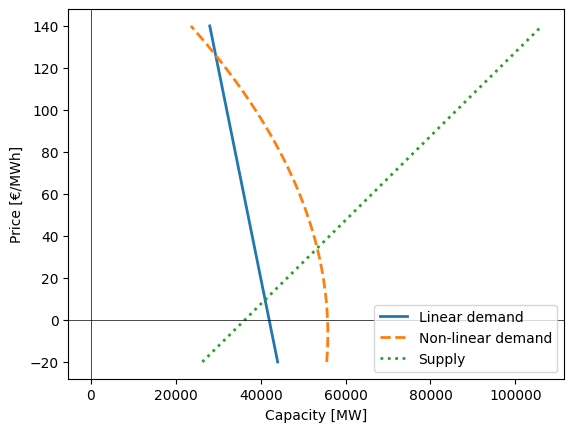

In [8]:
prices = np.linspace(-20, 140, num=1000)
demand = []
for t in range(1000):
    demand.append(DEMAND(
        price=prices[t],
        time=consumption_analysis_interval[0],
        lagged_price={-1:0},
        lagged_demand={-1:DEMAND.fallback(None)},
    ))

supply = [SUPPLY(prices[t], consumption_analysis_interval[0]) for t in range(len(prices))]
lin_demand = [LIN_DEMAND(prices[t], consumption_analysis_interval[0], lagged_price={-1:0}, lagged_demand={-1:LIN_DEMAND.fallback(None)}, past_inventory=0) for t in range(len(prices))]

plt.plot(lin_demand, prices, lw=2, label="Linear demand")
plt.plot(demand, prices, lw=2, label="Non-linear demand", ls="--")
plt.plot(supply, prices, lw=2, label="Supply", ls=":")
plt.axhline(0, ls="-", c="k", lw=0.5)
plt.axvline(0, ls="-", c="k", lw=0.5)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.legend()

## Check range

In [9]:
EQUILIBRIUM = NonLinEquilibrium(
    supply=SUPPLY, 
    demand=DEMAND,
    times=INTERVAL,
    analytical_solution=True
)
EQUILIBRIUM.clearing.demand

print(EQUILIBRIUM.clearing.price.min(), EQUILIBRIUM.clearing.price.max())

-0.9162995104362229 104.7072697123978


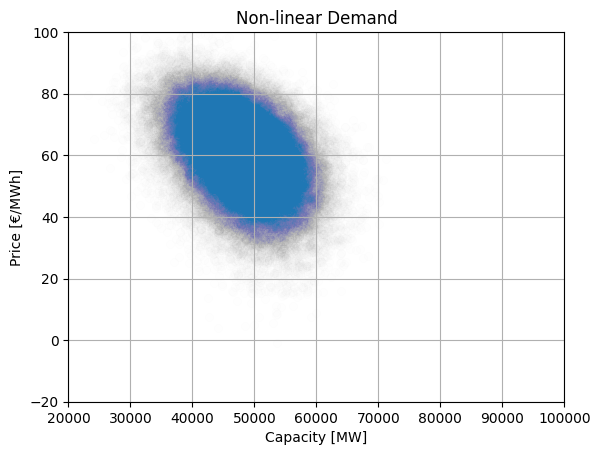

In [10]:
plt.scatter(EQUILIBRIUM.clearing.demand, EQUILIBRIUM.clearing.price, alpha=0.005)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.title("Non-linear Demand")
plt.xlim(20_000, 100_000)
plt.ylim(-20, 100)
plt.grid(True)


In [11]:
from synthetic import IndEquilibrium


LIN_EQUILIBRIUM = IndEquilibrium(
    supply=SUPPLY, 
    demand=LIN_DEMAND,
    times=INTERVAL,
    analytical_solution=True
)

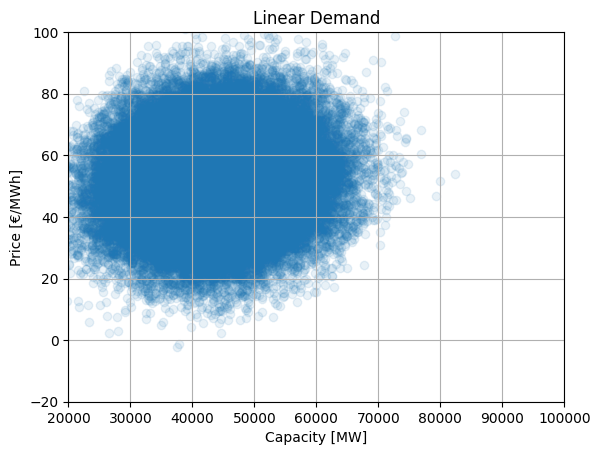

In [12]:
plt.scatter(LIN_EQUILIBRIUM.clearing.demand, LIN_EQUILIBRIUM.clearing.price, alpha=0.1)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.title("Linear Demand")
plt.xlim(20_000, 100_000)
plt.ylim(-20, 100)
plt.grid(True)


# Simulations

In [13]:
# # Create the empty lists to store the analysis output
# output_lists:dict[str, dict[str, list]] = {}
# for estimator in ESTIMATORS:
#     output_lists[estimator.name] = {"Mean":[],
#                                     "Upper":[],
#                                     "Lower":[]}



# simulation = Simulation(sample=sample)

# simulation.run_simulations_by_model(
#     runs=runs,
#     estimators=ESTIMATORS,
#     model=StructuralModel.Model_V,
#     demand_arg=0.9,
#     simulation_count=0,
#     wind_manual_ar_sum=wind_manual_ar_sum
# )

In [14]:
# simulation.report_as_text()

In [15]:
# simulation.models["I(W0, W0^2)-E(P0, P0^2)-C(W1:W26)_P0"]

## Plotting

In [16]:
from plot_tools import *
from matplotlib.axes import Axes
from matplotlib.lines import Line2D
import mpl_toolkits.axisartist as axisartist

In [17]:
def run_model_simulation(sample:int, estimators:list[ModelInputParams], runs:int, model:StructuralModel) -> tuple[list[list[float]], list[list[float]], list[list[float]], list[str]]:
    simulation = Simulation(sample=sample)

    
    simulation.run_simulations_by_model(runs=runs,
                                        estimators=estimators,
                                        model=model,
                                        demand_arg=0.6 if model in [StructuralModel.Model_I, StructuralModel.Model_V] else None,
                                        progress=False)
    
    results_p0:list[list[float]] = []
    results_p1:list[list[float]] = []
    results_psqr:list[list[float]] = []
    names = [est.latex_name for est in estimators]
    prev_model = list(simulation.models.keys())[0].split("_")[0]

    for name, estimator_results in simulation.models.items():
        # print(name, estimator_results.results)

        new_model = name.split("_")[0]
        if new_model != prev_model:
            prev_model = new_model
            for res_list in [results_p1, results_psqr]:
                if len(res_list) < len(results_p0):
                    res_list.append([])
                
        if "_" not in name or name.endswith("_P0"):
            results_p0.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P1"):
            results_p1.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P0^2"):
            results_psqr.append([res.estimate for res in estimator_results.results])
        else:
            pass
            # print(name)
    # This is needed just in case the last one also does not have an estimate for all of them!
    for res_list in [results_p1, results_psqr]:
        if len(res_list) < len(results_p0):
            res_list.append([])

    return results_p0, results_p1, results_psqr, names

In [18]:
def application_boxplot(results_p0:list[list[float]],
                        results_p1:list[list[float]], 
                        results_psqr:list[list[float]], 
                        names:list[str], 
                        output_file:str, 
                        xlim, 
                        own_price_elasticity, 
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):
        total_width = (WIDE_WIDTH-1) + 4
        fig, axss = plt.subplots(1, 2, sharex=False,  sharey=True, figsize=(total_width, HEIGHT), width_ratios=[(WIDE_WIDTH-1)/total_width, 4/total_width], subplot_kw={'axes_class': axisartist.Axes})
        # fig, ax0 = plt.subplots(1, 1, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})
        ax0: Axes = axss[0]
        ax1: Axes = axss[1]

        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))
       
        ticks: list[str] = list(reversed(names))
   
        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax0.boxplot(xx_p1, vert=False, patch_artist=True, notch=True)
        bplot3 = ax1.boxplot(xx_psqr, vert=False, patch_artist=True, notch=False)
   
        colors = ["darkorange", "dodgerblue", "darkgreen"]
        bbpp = [bplot1, bplot2, bplot3]
        bbpp = [bplot1, bplot3]
   
        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')
   
        legend_elements = [
            bplot1["boxes"][0], 
            bplot2["boxes"][0],
            bplot3["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
            Line2D([0], [0], color='darkgreen', linestyle="--",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)", 
            "estimated cross-price demand response $\\hat{\\beta}^{P1}$ ($P_{t-1}\\rightarrow D_t$)",
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)", 
            "true linear own-price demand response $\\beta^{PL}$",
            "true cross-price demand response $\\beta^{P1}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]
   
        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)
   
        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore
        
        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)
        
        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax0.axvline(x=cross_price_elasticity, ls=':', color='dodgerblue', lw=2, alpha=1)
        ax1.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax1.axvline(x=quadratic_elasticity, ls='--', color='darkgreen', lw=2, alpha=1)
   
        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-0.425, xmax=1, clip_on=False)
                ax1.axhline(y=h + 0.5, ls="-", color="grey", xmin=0, xmax=1, clip_on=False)
    
        # Add estimator validity table
        # plot_table(fig)
        
        
        # Remove duplicate y ticks from right subplot
        ax1.axis["left"].set_visible(False)    # type: ignore
        ax1.axvline(ax1.get_xlim()[0], ls="-", color="k", clip_on=False, lw=0.5)

        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center', 
                   ncol=2, bbox_to_anchor=(0.5, 0), fancybox=True, frameon=False, fontsize="large")
    
        save_figure(fig, output_file+"_application_figure", VERSION)
   
  

In [19]:
def application_boxplot(results_p0:list[list[float]],
                        _results_p1:list[list[float]], 
                        results_psqr:list[list[float]], 
                        names:list[str], 
                        output_file:str, 
                        xlim, 
                        own_price_elasticity, 
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):
        
        fig, ax0 = plt.subplots(1, 1, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})

        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        # xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))
       
        ticks: list[str] = list(reversed(names))
   
        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax0.boxplot(xx_psqr, vert=False, patch_artist=True, notch=True)
   
        colors = ["darkorange", "dodgerblue", "darkgreen"]
        # bbpp = [bplot1, bplot2, bplot3]
        bbpp = [bplot1, bplot2]
   
        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')
   
        legend_elements = [
            bplot1["boxes"][0], 
            bplot2["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)", 
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)", 
            "true linear own-price demand response $\\beta^{PL}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]
   
        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)
   
        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore
        
        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)
        
        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax0.axvline(x=quadratic_elasticity, ls=':', color='dodgerblue', lw=2, alpha=1)
   
        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-0.425, xmax=1, clip_on=False)
    
        # Add estimator validity table
        plot_table(fig)
        
        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center', 
                   ncol=2, bbox_to_anchor=(0.5, 0), fancybox=True, frameon=False, fontsize="large")
    
        save_figure(fig, output_file+"_application_figure", VERSION)
   
  

In [31]:
def plot_application_boxplot(sample:int, runs:int, output_file:str, model:StructuralModel, estimators:list[ModelInputParams]):
    
    results_p0, results_p1, results_psqr, names = run_model_simulation(
        model=model,
        estimators=estimators,
        sample=sample,
        runs=runs
    )
    
    xlims:dict[StructuralModel, tuple[float, float]] = {
        StructuralModel.Model_I:(-400, 100),
        StructuralModel.Model_II:(-200, 100),
        StructuralModel.Model_III:(-200, 100),
        StructuralModel.Model_V:(-51, 1),
    }

    application_boxplot(
        results_p0=results_p0,
        _results_p1=results_p1,
        results_psqr=results_psqr,
        names=names,
        output_file=output_file,
        xlim=xlims[model],
        own_price_elasticity=-100 if model != StructuralModel.Model_V else -20,
        cross_price_elasticity=50 if model == StructuralModel.Model_III else 0,
        quadratic_elasticity=-1.5,
        replace_ellipsis=False
    )

100%|██████████| 1/1 [00:52<00:00, 52.55s/it]


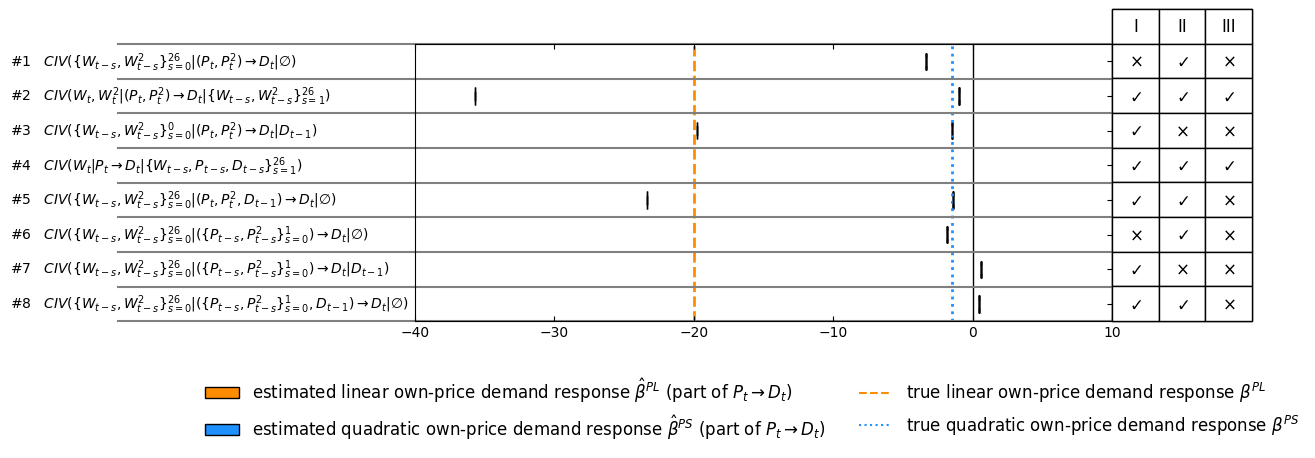

In [27]:
plot_application_boxplot(8760*1, 1, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

100%|██████████| 5/5 [07:46<00:00, 93.23s/it]


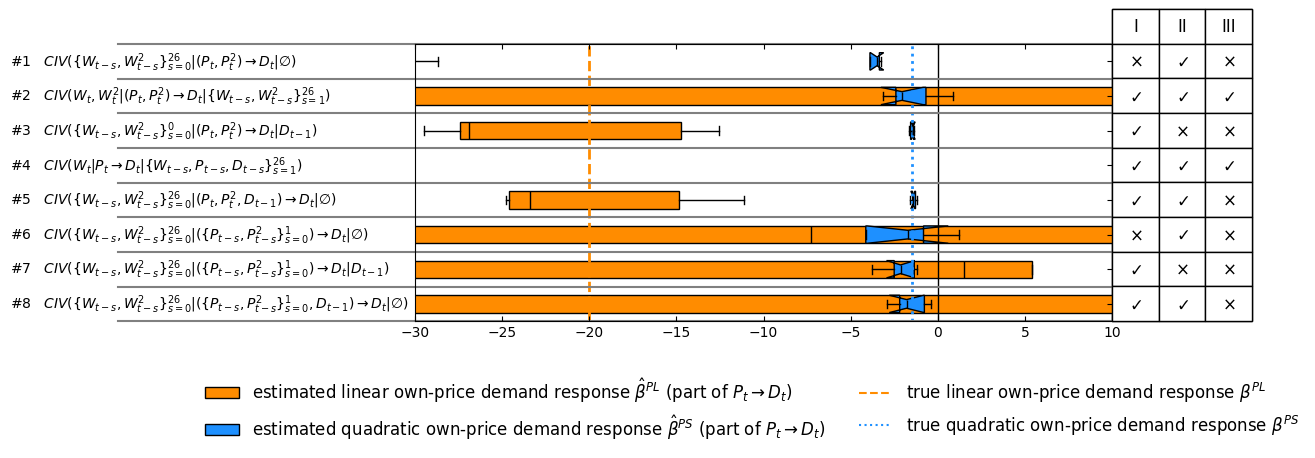

In [ ]:
plot_application_boxplot(8760*2, 5, "model_V_1_years_5_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

100%|██████████| 10/10 [40:03<00:00, 240.35s/it]


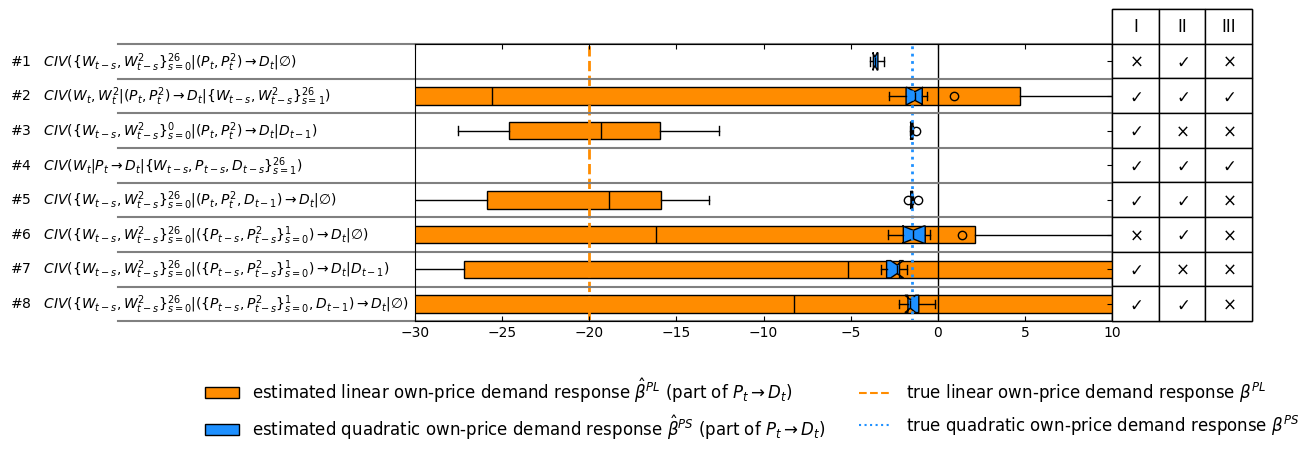

In [30]:
plot_application_boxplot(8760*5, 10, "model_V_5_years_10_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


 48%|████▊     | 48/100 [24:16:11<7:51:00, 543.47s/it]   

No real equilibrium price
Length mismatch: Expected axis has 31 elements, new values have 88272 elements


 63%|██████▎   | 63/100 [26:29:20<5:29:15, 533.94s/it]

No real equilibrium price
Length mismatch: Expected axis has 32 elements, new values have 88272 elements
No real equilibrium price
Length mismatch: Expected axis has 29 elements, new values have 88272 elements


 97%|█████████▋| 97/100 [31:07:38<27:26, 548.89s/it]  

No real equilibrium price
Length mismatch: Expected axis has 34 elements, new values have 88272 elements


100%|██████████| 100/100 [31:34:57<00:00, 1136.98s/it]


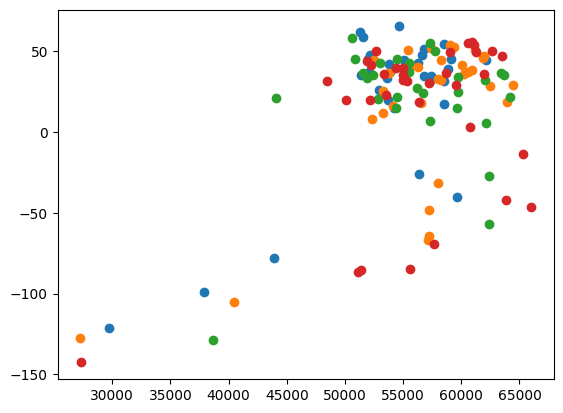

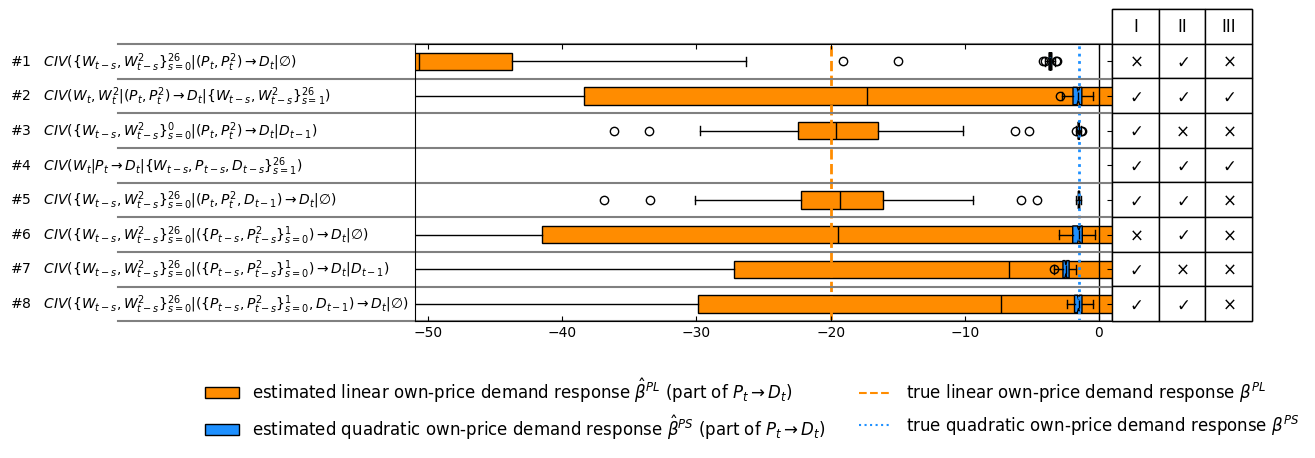

In [32]:
plot_application_boxplot(8760*10, 100, "model_V_10_years_100_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [ ]:
# plot_application_boxplot(8760*25, 50, "model_V_25_years_50_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [ ]:
# plot_application_boxplot(8760*10, 50, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

In [ ]:
# plot_application_boxplot(8760*5, 20, "model_V_5_years_20_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


# Plot from Felix

In [245]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels.iv import IV2SLS
from estimation import get_IV_model, IVModel, IVResults

from model import Dummy

In [246]:


# rng = np.random.default_rng(0)
# T = 100

# # -----------------------------
# # 1) Instrument z_t (persistent)
# # -----------------------------
# z = rng.normal(size=T)
# for t in range(1, T):
#     z[t] = 0.8 * z[t - 1] + rng.normal()

# # -----------------------------------------
# # 2) Structural error u_t (serially corr HAC)
# # -----------------------------------------
# u = rng.normal(size=T)
# for t in range(1, T):
#     u[t] = 0.7 * u[t - 1] + rng.normal()

# # -----------------------------------------
# # 3) Endogeneity: v correlated with u
# # -----------------------------------------
# v = 0.8 * u + 0.6 * rng.normal(size=T)

# # ---------------------------------------------------
# # 4) First stage: x depends on z and z^2 (strong IV)
# # ---------------------------------------------------
# x = 0.9 * z + 0.8 * (z**2) + v

# # True structural function
# b_true = np.array([0.5, 1.0, -0.4]) # (const, x, x^2)
# y = b_true[0] + b_true[1] * x + b_true[2] * x**2 + u

# df = pd.DataFrame({"y": y, "x": x, "z": z})
# df["y_t-1"] = df["y"].shift(1)
# df["x2"] = df["x"] ** 2
# df["z2"] = df["z"] ** 2
# df["z3"] = df["z"] ** 3

# # ------------------------------------------------------
# # 5) 2SLS: treat x and x^2 as endogenous
# # instrument with z, z^2, z^3 (overidentified)
# # HAC covariance via kernel (Bartlett)
# # ------------------------------------------------------
# mod = IV2SLS(
# dependent=df["y"],
# exog=pd.DataFrame({"const": 1.0}, index=df.index),
# endog=df[["x", "x2", "y_t-1"]],
# instruments=df[["z", "z2", "z3"]],
# )

# res = mod.fit(
# cov_type="kernel",
# kernel="bartlett",
# bandwidth=12,
# debiased=True,
# )

# print(res.summary)

# # ------------------------------------------------------
# # 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# # ------------------------------------------------------
# cols = ["const", "x", "x2"]
# beta_hat = res.params[cols].to_numpy()
# V_hat = res.cov.loc[cols, cols].to_numpy()

# xgrid = np.linspace(df["x"].quantile(0.02), df["x"].quantile(0.98), 200)
# Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

# f_hat = Zgrid @ beta_hat
# f_true = Zgrid @ b_true

# B = 5000
# beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
# f_draws = beta_draws @ Zgrid.T # (B,m)

# # Pointwise 95% band (separate quantiles at each x)
# lo_pw = np.quantile(f_draws, 0.025, axis=0)
# hi_pw = np.quantile(f_draws, 0.975, axis=0)

# # Uniform 95% band (controls max deviation over the whole grid)
# dev = np.max(np.abs(f_draws - f_hat), axis=1)
# c = np.quantile(dev, 0.95)
# lo_u, hi_u = f_hat - c, f_hat + c

# # ------------------------------------------------------
# # 7) Plot: data, true curve, estimated curve, bands
# # ------------------------------------------------------
# plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
# plt.plot(xgrid, f_true, linewidth=2, label="true f(x)")
# plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x)")
# plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
# plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
# plt.xlabel("x")
# plt.ylabel("y")
# plt.legend()
# plt.title("2SLS with HAC cov: simulated function bands + true function")
# plt.show()

In [247]:
# rng = np.random.default_rng(0)

# # -----------------------------
# # 1) Instrument z_t (persistent)
# # -----------------------------
# z = EQUILIBRIUM.supply.wind

# # -----------------------------------------
# # 2) Structural error u_t (serially corr HAC)
# # -----------------------------------------
# u = None

# # -----------------------------------------
# # 3) Endogeneity: v correlated with u
# # -----------------------------------------
# v = None

# # ---------------------------------------------------
# # 4) First stage: x depends on z and z^2 (strong IV)
# # ---------------------------------------------------
# x = EQUILIBRIUM.clearing.price

# # True structural function
# b_true = np.array([EQUILIBRIUM.demand.base_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr]) # (const, x, x^2)
# y = EQUILIBRIUM.clearing.demand

# df = pd.DataFrame({"y": y, "x": x, "z": z})

# # ------------------------------------------------------
# # 5) 2SLS: treat x and x^2 as endogenous
# # instrument with z, z^2, z^3 (overidentified)
# # HAC covariance via kernel (Bartlett)
# # ------------------------------------------------------

# model: IVModel = get_IV_model(
#     demand=y, price=x, wind=z, 
#     series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
#     model=ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=26),
#     controls=False
# )
# res: IVResults = model.fitted_model  # type: ignore

# print(res.summary)

# # ------------------------------------------------------
# # 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# # ------------------------------------------------------
# cols = ["constant", "price", "price_t^2"]
# other_cols = [var for var in res.params.index if not var in cols]

# beta_hat = res.params[cols].to_numpy()
# beta_hat_others = res.params[other_cols].to_numpy()
# V_hat = res.cov.loc[cols, cols].to_numpy()
# beta_hat_alt = res.params[cols].to_numpy()
# beta_hat_alt[0] = EQUILIBRIUM.demand.base_constant

# xgrid = np.linspace(df["x"].quantile(0.02), df["x"].quantile(0.98), 200)
# Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

# w = model.data.exogenous[other_cols].mean() @ beta_hat_others
# avg_conditions = w.sum()

# f_hat = Zgrid @ beta_hat + avg_conditions
# f_true = Zgrid @ b_true
# f_hat_alt = Zgrid @ beta_hat_alt

# B = 5000
# beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
# f_draws = beta_draws @ Zgrid.T + avg_conditions # (B,m) 

# beta_draws_alt = rng.multivariate_normal(mean=beta_hat_alt, cov=V_hat, size=B) # (B,3)
# f_draws_alt = beta_draws_alt @ Zgrid.T # (B,m) 

# # Pointwise 95% band (separate quantiles at each x)
# lo_pw = np.quantile(f_draws, 0.025, axis=0)
# hi_pw = np.quantile(f_draws, 0.975, axis=0)

# lo_pw_alt = np.quantile(f_draws_alt, 0.025, axis=0)
# hi_pw_alt = np.quantile(f_draws_alt, 0.975, axis=0)

# # Uniform 95% band (controls max deviation over the whole grid)
# dev = np.max(np.abs(f_draws - f_hat), axis=1)
# c = np.quantile(dev, 0.95)
# lo_u, hi_u = f_hat - c, f_hat + c

# dev_alt = np.max(np.abs(f_draws_alt - f_hat_alt), axis=1)
# c = np.quantile(dev_alt, 0.95)
# lo_u_alt, hi_u_alt = f_hat_alt - c, f_hat_alt + c

# # ------------------------------------------------------
# # 7) Plot: data, true curve, estimated curve, bands
# # ------------------------------------------------------
# plt.figure()
# # plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
# plt.plot(xgrid, f_true, linewidth=2, label="true f(x)", color="darkred")
# # plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x)", color="darkorange")
# plt.plot(xgrid, f_hat_alt, linewidth=2, label="2SLS f_hat(x)", color="darkorange")
# # plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
# # plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
# plt.fill_between(xgrid, lo_pw_alt, hi_pw_alt, alpha=0.2, label="pointwise 95% band", color="dodgerblue")
# plt.fill_between(xgrid, lo_u_alt, hi_u_alt, alpha=0.15, label="uniform 95% band", color="darkorange")
# plt.xlabel("x")
# plt.ylabel("y")
# plt.legend()
# plt.title("2SLS with HAC cov: simulated function bands + true function")
# plt.show()

## CIV Wind

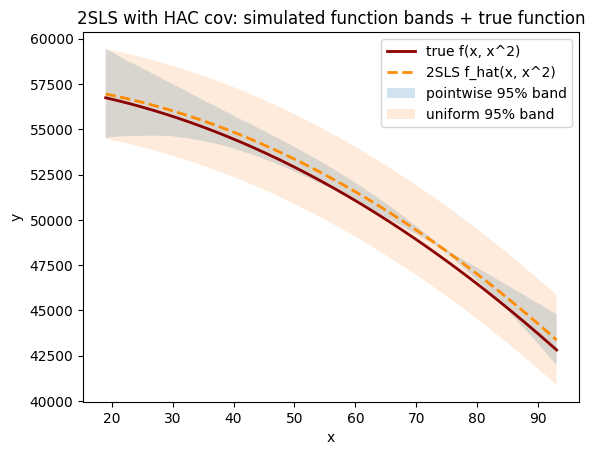

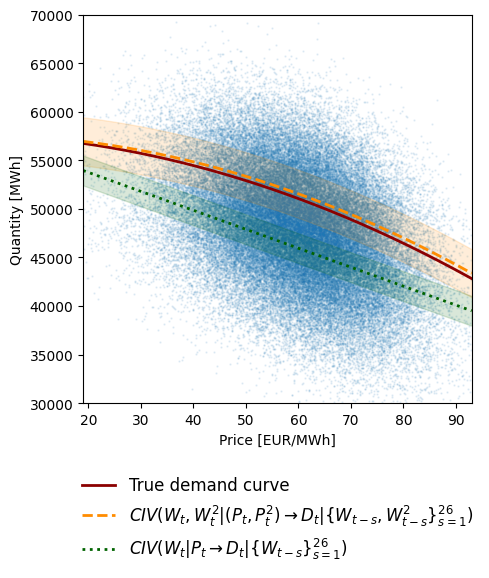

In [258]:
rng = np.random.default_rng(0)

EST_1 = ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=26)
EST_2 = ModelInputParams(IVOptions.CONDITIONAL_WIND, order=26)
EST_3 = ModelInputParams(IVOptions.NL_REGULAR, order=26)

# -----------------------------
# 1) Instrument z_t (persistent)
# -----------------------------
z = EQUILIBRIUM.supply.wind

# -----------------------------------------
# 2) Structural error u_t (serially corr HAC)
# -----------------------------------------
u = None

# -----------------------------------------
# 3) Endogeneity: v correlated with u
# -----------------------------------------
v = None

# ---------------------------------------------------
# 4) First stage: x depends on z and z^2 (strong IV)
# ---------------------------------------------------
x = EQUILIBRIUM.clearing.price

# True structural function
b_true = np.array([EQUILIBRIUM.demand.base_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr]) # (const, x, x^2)
y = EQUILIBRIUM.clearing.demand

df = pd.DataFrame({"y": y, "x": x, "z": z})

# ------------------------------------------------------
# 5) 2SLS: treat x and x^2 as endogenous
# instrument with z, z^2, z^3 (overidentified)
# HAC covariance via kernel (Bartlett)
# ------------------------------------------------------

model_sqr: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=EST_1,
    controls=False
)
res_sqr: IVResults = model_sqr.fitted_model  # type: ignore

# print(res_sqr.summary)

# ------------------------------------------------------
# 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# ------------------------------------------------------
cols = ["constant", "price", "price_t^2"]

beta_hat = res_sqr.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant
V_hat = res_sqr.cov.loc[cols, cols].to_numpy()

thsh = 0.001
min_x, max_x = df["x"].quantile(thsh), df["x"].quantile(1-thsh)
# min_x, max_x = -10, 120
xgrid = np.linspace(min_x, max_x, num=300)
# xgrid = np.linspace(-10, 120, 500)
Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

f_hat = Zgrid @ beta_hat
f_true = Zgrid @ b_true

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw = np.quantile(f_draws, 0.025, axis=0)
hi_pw = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat), axis=1)
c = np.quantile(dev, 0.95)
lo_u, hi_u = f_hat - c, f_hat + c

# ------------------------------------------------------
# 6) Linear case
# ------------------------------------------------------

model_lin: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=EST_2,
    controls=False
)
res_lin: IVResults = model_lin.fitted_model  # type: ignore

# print(res_lin.summary)

cols = ["constant", "price"]

beta_hat = res_lin.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant #+ EQUILIBRIUM.demand.b_sqr*(EQUILIBRIUM.demand.average_supply_price**2)
# beta_hat = res_lin.params[cols].to_numpy()
V_hat = res_lin.cov.loc[cols, cols].to_numpy()

Zgrid = np.column_stack([np.ones_like(xgrid), xgrid])

f_hat_lin = Zgrid @ beta_hat

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw_lin = np.quantile(f_draws, 0.025, axis=0)
hi_pw_lin = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat_lin), axis=1)
c = np.quantile(dev, 0.95)
lo_u_lin, hi_u_lin = f_hat_lin - c, f_hat_lin + c

# # ------------------------------------------------------
# # 7) ESTIMATOR 3
# # ------------------------------------------------------

# model_3: IVModel = get_IV_model(
#     demand=y, price=x, wind=z, 
#     series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
#     model=EST_3,
#     controls=False
# )
# res_naive: IVResults = model_3.fitted_model  # type: ignore

# cols = ["constant", "price", "price_t^2"]

# beta_hat = res_naive.params[cols].to_numpy()
# beta_hat[0] = EQUILIBRIUM.demand.base_constant
# V_hat = res_naive.cov.loc[cols, cols].to_numpy()

# # xgrid = np.linspace(-10, 120, 500)
# Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

# f_hat_naive = Zgrid @ beta_hat

# B = 5000
# beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
# f_draws = beta_draws @ Zgrid.T # (B,m) 

# # Pointwise 95% band (separate quantiles at each x)
# lo_pw = np.quantile(f_draws, 0.025, axis=0)
# hi_pw = np.quantile(f_draws, 0.975, axis=0)

# # Uniform 95% band (controls max deviation over the whole grid)
# dev = np.max(np.abs(f_draws - f_hat), axis=1)
# c = np.quantile(dev, 0.95)
# lo_u_naive, hi_u_naive = f_hat - c, f_hat + c


# ------------------------------------------------------
# 8) Plot: data, true curve, estimated curve, bands
# ------------------------------------------------------

plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

fig = plt.figure(figsize=(5, 6))
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.scatter(x, y, s=0.5, alpha=0.1)
plt.plot(xgrid, f_true, linewidth=2, label="True demand curve", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label=EST_1.latex_name, color="darkorange", ls="--")
plt.plot(xgrid, f_hat_lin, linewidth=2, label=EST_2.latex_name, color="darkgreen", ls=":")
# plt.plot(xgrid, f_hat_naive, linewidth=2, label=EST_3.latex_name, color="dodgerblue", ls="-.")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="", color="darkorange")
plt.fill_between(xgrid, lo_u_lin, hi_u_lin, alpha=0.15, label="", color="darkgreen")
# plt.fill_between(xgrid, lo_u_naive, hi_u_naive, alpha=0.15, label="", color="dodgerblue")
plt.xlabel("Price [EUR/MWh]")
plt.ylabel("Quantity [MWh]")
plt.xlim(min_x, max_x)
plt.ylim(30_000, 70_000)
plt.legend(loc='upper center', ncol=1, bbox_to_anchor=(0.5, -0.15), fancybox=True, frameon=False, fontsize="large")
# plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.tight_layout()
plt.show()
save_figure(fig, "non_linear_curve", VERSION)

## NIV

In [249]:
ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1, order_w=26).latex_name

'$CIV(\\{W_{{t-s}}, W^2_{{t-s}}\\}_{s=0}^{26}|(P_t, P_t^2)\\rightarrow D_t|D_{t-1})$'

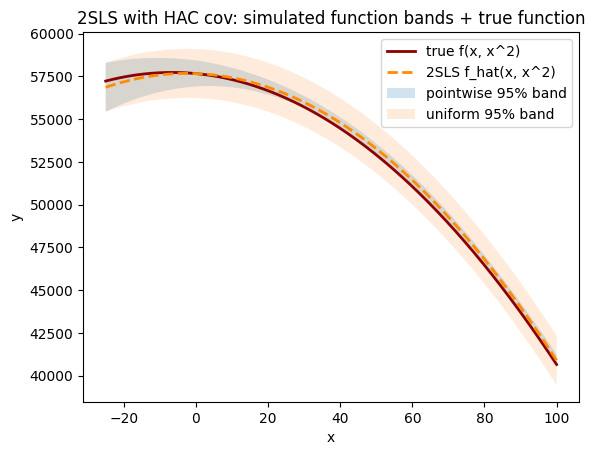

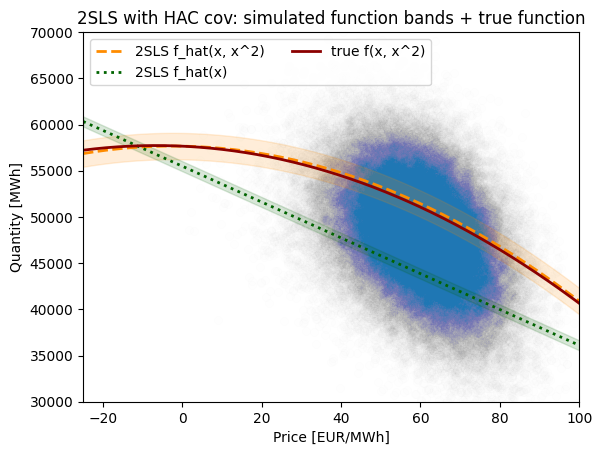

In [250]:
rng = np.random.default_rng(0)
# T = 8760*1

# -----------------------------
# 1) Instrument z_t (persistent)
# -----------------------------
z = EQUILIBRIUM.supply.wind

# -----------------------------------------
# 2) Structural error u_t (serially corr HAC)
# -----------------------------------------
u = None

# -----------------------------------------
# 3) Endogeneity: v correlated with u
# -----------------------------------------
v = None

# ---------------------------------------------------
# 4) First stage: x depends on z and z^2 (strong IV)
# ---------------------------------------------------
x = EQUILIBRIUM.clearing.price

# True structural function
b_true = np.array([EQUILIBRIUM.demand.base_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr]) # (const, x, x^2)
y = EQUILIBRIUM.clearing.demand

df = pd.DataFrame({"y": y, "x": x, "z": z})

# ------------------------------------------------------
# 5) 2SLS: treat x and x^2 as endogenous
# instrument with z, z^2, z^3 (overidentified)
# HAC covariance via kernel (Bartlett)
# ------------------------------------------------------

model_sqr: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1),
    controls=False
)
res_sqr: IVResults = model_sqr.fitted_model  # type: ignore

# print(res_sqr.summary)

# ------------------------------------------------------
# 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# ------------------------------------------------------
cols = ["constant", "price", "price_t^2"]

beta_hat = res_sqr.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant
V_hat = res_sqr.cov.loc[cols, cols].to_numpy()

min_x, max_x = df["x"].quantile(0.002), df["x"].quantile(0.998)
min_x, max_x = -25, 100
xgrid = np.linspace(min_x, max_x, 300)
# xgrid = np.linspace(-10, 120, 500)
Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

f_hat = Zgrid @ beta_hat
f_true = Zgrid @ b_true

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw = np.quantile(f_draws, 0.025, axis=0)
hi_pw = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat), axis=1)
c = np.quantile(dev, 0.95)
lo_u, hi_u = f_hat - c, f_hat + c

# ------------------------------------------------------
# 6) Linear case
# ------------------------------------------------------

model_lin: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=ModelInputParams(IVOptions.CONDITIONAL_DEMAND, order=1),
    controls=False
)
res_lin: IVResults = model_lin.fitted_model  # type: ignore

# print(res_lin.summary)

cols = ["constant", "price"]

beta_hat = res_lin.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant + EQUILIBRIUM.demand.b_sqr*(EQUILIBRIUM.demand.average_supply_price**2)
V_hat = res_lin.cov.loc[cols, cols].to_numpy()

Zgrid = np.column_stack([np.ones_like(xgrid), xgrid])

f_hat_lin = Zgrid @ beta_hat

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw_lin = np.quantile(f_draws, 0.025, axis=0)
hi_pw_lin = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat_lin), axis=1)
c = np.quantile(dev, 0.95)
lo_u_lin, hi_u_lin = f_hat_lin - c, f_hat_lin + c

# ------------------------------------------------------
# 7) Plot: data, true curve, estimated curve, bands
# ------------------------------------------------------
plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.scatter(x, y, alpha=0.005)
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.plot(xgrid, f_hat_lin, linewidth=2, label="2SLS f_hat(x)", color="darkgreen", ls=":")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="", color="darkorange")
plt.fill_between(xgrid, lo_u_lin, hi_u_lin, alpha=0.15, label="", color="darkgreen")
plt.xlabel("Price [EUR/MWh]")
plt.ylabel("Quantity [MWh]")
plt.xlim(min_x, max_x)
plt.ylim(30_000, 70_000)
plt.legend(ncols=2)
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

# LaTeX names

In [251]:
import matplotlib.pyplot as plt

def visualize_latex(latex:str) -> None:

    fig = plt.figure(figsize=(4, 1))
    plt.text(0.5, 0.5, latex, fontsize=20, ha='center', va='center')
    plt.axis('off')

    plt.savefig("latex.png", dpi=200, bbox_inches='tight', pad_inches=0.1)
    plt.show()

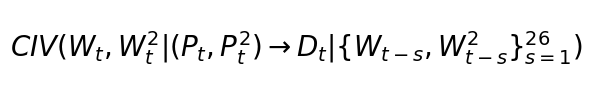

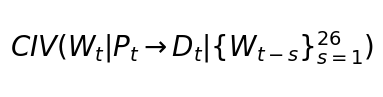

In [252]:
visualize_latex(ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=26).latex_name)
visualize_latex(ModelInputParams(IVOptions.CONDITIONAL_WIND, order=26).latex_name)

In [253]:
beta_draws

array([[55444.60533332,  -194.44530473],
       [55484.79237649,  -193.70369114],
       [55386.16242604,  -194.25439392],
       ...,
       [55555.07970906,  -196.09217078],
       [55153.47144082,  -192.01747201],
       [55745.20080057,  -196.30342277]], shape=(5000, 2))